# GameTheory 04g — Supermodularité et treillis des équilibria

**Navigation** : [<< 4e-Reflective-Oracles](GameTheory-04e-Reflective-Oracles-Python.ipynb) | [Index](README.md)

**Autres approfondissements de 04** : [4-NashEquilibrium (track principal)](GameTheory-04-NashEquilibrium-Python.ipynb) · [4b-Lean-NashExistence](GameTheory-04b-Lean-NashExistence-Lean.ipynb) · [4c-NashExistence](GameTheory-04c-NashExistence-Python.ipynb) · [4d-Marchandage-Asymetrique](GameTheory-04d-Marchandage-Asymetrique-Python.ipynb) · [4e-Reflective-Oracles](GameTheory-04e-Reflective-Oracles-Python.ipynb) · [4h-Routing-PriceOfAnarchy](GameTheory-04h-Routing-PriceOfAnarchy-Python.ipynb)

**Kernel** : .NET C#

**Version jumelle** : [Python](GameTheory-04g-Supermodularite-Python.ipynb).

**Source primaire** : carnet Python versionné. Bibliographie héritée, sans nouvelle lecture revendiquée.

***

## Introduction

Les carnets [4](GameTheory-04-NashEquilibrium-Python.ipynb) et [4c](GameTheory-04c-NashExistence-Python.ipynb) traitent l'équilibre de Nash comme un **point** : on le calcule, et on démontre qu'il existe par un argument de point fixe.

Ce carnet pose une question différente, de **structure** : quand les gains d'un jeu ont une forme de complémentarité, que peut-on dire de l'**ensemble** des équilibria purs ? Réponse : cet ensemble est un **treillis** — il possède un plus petit et un plus grand élément, et il se compare de façon monotone quand un paramètre du jeu varie. C'est le contenu du théorème de Topkis, popularisé en théorie des jeux par Milgrom et Roberts (1990) et Vives (1990).

Le fil du carnet :

1. **Définitions** : treillis produit, fonction supermodulaire, différences croissantes.
2. **Compléments vs substituts stratégiques** : la monotonie de la correspondance de meilleure réponse.
3. **Treillis des équilibria purs** : existence d'un plus petit et d'un plus grand équilibre ; clôture ambiante vérifiée sur un exemple.
4. **Comparaison monotone** : quand la valeur d'une action augmente, les équilibres extrêmes ne descendent pas.
5. **Ce que ce treillis n'est pas** : la distinction avec le treillis des matchings stables (Roth), qui ordonne des appariements par des préférences.

### Objectifs d'apprentissage

A l'issue de ce carnet, vous saurez :

1. Définir un treillis produit, une fonction supermodulaire et la propriété de différences croissantes.
2. **Tester** la supermodularité d'un jeu sur sa matrice de gains, et repérer une paire qui viole la condition.
3. Caractériser les **compléments** et **substituts** stratégiques par la monotonie de la correspondance de meilleure réponse.
4. Vérifier computationnellement que l'ensemble des équilibria purs d'un jeu supermodulaire est un **treillis**, avec plus petit et plus grand élément.
5. Établir une **comparaison monotone** : quand un paramètre augmente, les équilibres extrêmes ne descendent pas.
6. **Distinguer** le treillis des équilibria (ordre composante par composante sur des profils d'actions) du treillis des matchings stables (ordre défini par des préférences).

### Durée estimée : 45 minutes

### Prérequis

- [GameTheory-02-NormalForm](GameTheory-02-NormalForm-Python.ipynb) : jeux à forme normale, dominance, meilleure réponse
- [GameTheory-04-NashEquilibrium](GameTheory-04-NashEquilibrium-Python.ipynb) : équilibre de Nash pur et mixte
- [GameTheory-04c-NashExistence](GameTheory-04c-NashExistence-Python.ipynb) : existence par point fixe
- C# et .NET interactif

> *Ancres savantes — Topkis, D.M. (1978), Minimizing a Submodular Function on a Lattice, Operations Research 26(2):305-321 (le théorème de comparaison monotone pour les optimiseurs paramètres, fondement des sections 3 et 4) ; Milgrom, P. et Roberts, J. (1990), Rationalizability, Learning, and Equilibrium in Games with Strategic Complementarities, Econometrica 58(6):1255-1277 (les compléments stratégiques et le treillis des équilibria, sujet titulaire de ce carnet) ; Vives, X. (1990), Nash Equilibrium with Strategic Complementarities, Journal of Mathematical Economics 19(3):305-321 (existence et comparaison des équilibria dans les jeux à compléments) ; Zhou, L. (1994), The Set of Nash Équilibria of a Supermodular Game is a Complete Lattice, Games and Economic Behavior 7(2):295-300 (la complétude du treillis ordonné, illustrée section 3) ; Gale, D. et Shapley, L.S. (1962), College Admissions and the Stability of Marriage, American Mathematical Monthly 69(1):9-15, et Roth, A.E. et Sotomayor, M.A.O. (1990), Two-Sided Matching, Cambridge University Press (le treillis des matchings stables, distingue section 5).*


## 1. Treillis, supermodularité et différences croissantes

### 1.1 Le treillis produit

On restreint chaque joueur à un ensemble fini d'actions totalement ordonne,
$A_i = \{0, 1, \dots, n_i-1\}$ (par exemple : niveau d'effort, qualité, capacité).
L'espace des profils est le **produit** $X = A_1 \times A_2$, muni de l'ordre
**composante par composante** :

$$x \le y \iff x_1 \le y_1 \ \text{et}\ x_2 \le y_2.$$

Deux profils quelconques $x$ et $y$ ont toujours une **borne inferieure** et une
**borne superieure** dans cet ordre :

$$x \wedge y = (\min(x_1,y_1),\ \min(x_2,y_2)), \qquad
  x \vee y = (\max(x_1,y_1),\ \max(x_2,y_2)).$$

C'est cette propriété — deux éléments ont toujours un meet et un join — qui fait
de $X$ un **treillis**.

> **Attention** : dans le plan, l'ordre composante par composante n'est **pas**
> un ordre total. Les profils $(1,2)$ et $(2,1)$ sont **incomparables** : ni l'un
> ni l'autre n'est plus grand. C'est précisément ce qui rend le treillis
> intéressant — et ce qu'un simple tri ne montrerait pas.

### 1.2 Fonction supermodulaire

Une fonction $f : X \to \mathbb{R}$ est **supermodulaire** si, pour tous $x, y \in X$ :

$$f(x \vee y) + f(x \wedge y) \ge f(x) + f(y).$$

En mots : les deux profils << mélanges >> (le meet et le join) valent **au moins**
les deux profils d'origine pris séparément. C'est une forme de **complémentarité** :
les coordonnées se renforcent mutuellement.

### 1.3 Différences croissantes

Pour un jeu à deux joueurs, la condition s'écrit plus concrètement sur la matrice
de gains. Le gain du joueur 1 a des **différences croissantes** en $(a_1, a_2)$ si,
pour $a_1 \le a_1'$ et $a_2 \le a_2'$ :

$$u_1(a_1', a_2') - u_1(a_1, a_2') \ \ge \ u_1(a_1', a_2) - u_1(a_1, a_2).$$

Autrement dit : **le gain marginal d'augmenter son action ne diminue pas quand
l'adversaire augmente la sienne**.

**Lemme de Topkis (cas des chaînes finies).** Sur un produit de chaînes, une
fonction est supermodulaire **si et seulement si** elle a des différences
croissantes en toute paire de coordonnées. Les deux tests sont donc équivalents —
nous allons le vérifier sur ordinateur plutot que de le postuler.

> **Remarque de vocabulaire.** << Supermodulaire >> au sens de ce carnet (gains
> stratégiques) n'est pas le même objet que le jeu **coopératif convexe** de la
> série, ou une fonction de coalition est dite supermodulaire quand les
> contributions marginales croissent avec la coalition. Les deux notions
> partagent le mot et l'idée de complémentarité, mais vivent sur des treillis
> différents : ici, des profils d'actions ; la, des sous-ensembles de joueurs.

In [1]:
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Text;
using Microsoft.DotNet.Interactive.Formatting;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
// Les figures conservent leur MIME SVG même à la consultation hors kernel.
record Svg(string Content);
Formatter.Register<Svg>((plot, writer) => writer.Write(plot.Content), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Svg), "image/svg+xml");
Console.WriteLine("Configuration C# : calculs finis et affichage SVG");


Configuration C# : calculs finis et affichage SVG


### Interprétation : configuration de l'environnement

Le Python primaire réutilise l'organe de série `game_theory_utils.py`. Le parallèle C# expose les mêmes opérations finies :

| Opération du Python | Parallèle C# | Rôle dans ce carnet |
|---|---|---|
| `NormalFormGame` | matrices de gains `double[,]` | représentation bimatrice des deux joueurs |
| `find_pure_nash` | `PureNash` | énumération exacte des équilibres purs, réutilisée en section 3 |
| `gale_shapley` | `GaleShapley` | propositions et appariement stable, réutilisés en section 5 |

Les objets supplémentaires de ce carnet sont les treillis, la supermodularité et la clôture ; l'énumération des profils et l'appariement gardent les mêmes définitions que dans le Python. Les figures sont émises au format `image/svg+xml`.

**Déterminisme** : les cellules énumèrent exhaustivement des ensembles finis. Aucun tirage aléatoire n'intervient ; les mêmes données produisent les mêmes résultats d'une exécution à l'autre.


### 1.4 Tester la supermodularité sur une matrice de gains

On implémente les deux tests de la section 1.2 et 1.3, puis on les applique à deux jeux de nature opposée :

- un jeu de **standard technologique** : l'action 0 est l'ancien standard, les
  actions 1 et 2 sont deux variantes d'un standard moderne. Se coordonner sur une
  variante moderne rapporte 2, toute autre combinaison rapporte 0 ;
- un jeu de **concurrence en quantité** (Cournot), ou augmenter sa quantité est
  d'autant moins rentable que l'adversaire produit déjà beaucoup.

In [2]:
// Les deux tests énumèrent respectivement les paires ordonnées et les rectangles stricts.
IEnumerable<(int, int)> Grid(int n, int m) =>
    from a in Enumerable.Range(0, n)
    from b in Enumerable.Range(0, m)
    select (a, b);
(int, int) Meet((int, int) x, (int, int) y) =>
    (Math.Min(x.Item1, y.Item1), Math.Min(x.Item2, y.Item2));
(int, int) Join((int, int) x, (int, int) y) =>
    (Math.Max(x.Item1, y.Item1), Math.Max(x.Item2, y.Item2));
bool Leq((int, int) x, (int, int) y) => x.Item1 <= y.Item1 && x.Item2 <= y.Item2;
(int Count, List<((int, int), (int, int), double, double)> Violations) Supermodular(double[,] u)
{
    var errors = new List<((int, int), (int, int), double, double)>();
    foreach (var x in Grid(u.GetLength(0), u.GetLength(1)))
    foreach (var y in Grid(u.GetLength(0), u.GetLength(1)))
    {
        var lo = Meet(x, y);
        var hi = Join(x, y);
        double lhs = u[lo.Item1, lo.Item2] + u[hi.Item1, hi.Item2];
        double rhs = u[x.Item1, x.Item2] + u[y.Item1, y.Item2];
        if (lhs < rhs - 1e-12)
            errors.Add((x, y, lhs, rhs));
    }
    return (errors.Count, errors);
}
(int Count, List<((int, int), (int, int), double, double)> Violations) IncreasingDifferences(
    double[,] u
)
{
    var errors = new List<((int, int), (int, int), double, double)>();
    int n = u.GetLength(0),
        m = u.GetLength(1);
    for (int a = 0; a < n; a++)
    for (int a2 = a + 1; a2 < n; a2++)
    for (int b = 0; b < m; b++)
    for (int b2 = b + 1; b2 < m; b2++)
    {
        double high = u[a2, b2] - u[a, b2],
            low = u[a2, b] - u[a, b];
        if (high < low - 1e-12)
            errors.Add(((a, b), (a2, b2), high, low));
    }
    return (errors.Count, errors);
}
var threshold = new double[,]
{
    { 0, 0, 0 },
    { 0, 2, 2 },
    { 0, 2, 2 },
};
var cournot = new double[10, 10];
for (int a = 0; a < 10; a++)
for (int b = 0; b < 10; b++)
    cournot[a, b] = a * (10 - a - b);
foreach (var (name, u) in new[] { ("standard / modernisation", threshold), ("Cournot", cournot) })
    Console.WriteLine(
        $"{name} : supermodulaire={Supermodular(u).Count == 0}, différences croissantes={IncreasingDifferences(u).Count == 0}, violations=({Supermodular(u).Count}, {IncreasingDifferences(u).Count})"
    );


standard / modernisation : supermodulaire=True, différences croissantes=True, violations=(0, 0)


Cournot : supermodulaire=False, différences croissantes=False, violations=(4050, 2025)


### Interprétation : deux structures opposées

Les deux tests — supermodularité et différences croissantes — donnent le **même
verdict** sur les deux jeux, ce qui illustre le lemme de Topkis dans le cas des
chaînes finies.

| Jeu | Supermodulaire | Différences croissantes | Structure |
|-----|----------------|-------------------------|-----------|
| Standard / modernisation | **Oui** | **Oui** | compléments stratégiques |
| Cournot | **Non** | **Non** | substituts stratégiques |

**Pourquoi le jeu de standard est-il supermodulaire ?** Prenez deux profils
$x = (1,2)$ et $y = (2,1)$. Leur meet est $(1,1)$ et leur join $(2,2)$. On a
$f(2,2) + f(1,1) = 2 + 2 = 4$ et $f(1,2) + f(2,1) = 2 + 2 = 4$ : l'égalité tient.
Prenez maintenant $x = (0,0)$ et $y = (1,1)$ : le meet est $(0,0)$, le join
$(1,1)$, donc $2 + 0 = 2 \ge 0 + 2$. La coordination sur le moderne ne crée de la
valeur que si **les deux** joueurs y sont : c'est exactement la complémentarité.

**Pourquoi Cournot est-il submodulaire ?** La dérivée croisée du gain
$u_1 = a(10 - a - b)$ vaut $\partial^2 u_1 / \partial a \partial b = -1 < 0$ :
chaque unité produite par l'adversaire **retire** de la rentabilité marginale de
ma propre production. Les actions se substituent au lieu de se renforcer.

> **Ce que le test ne dit pas.** La supermodularité est une propriété de la
> **forme des gains**, pas une propriété du jeu d'équilibres. Deux jeux
> supermodulaires peuvent avoir des ensembles d'équilibria très différents —
> c'est l'objet de la section 3.

### Exercice 1 — Classifier un jeu par ses gains

Soit le jeu bi-matrice ci-dessous, où chaque joueur veut **différer** de l'autre
et où la coordonnée $(2,2)$ est un refuge de faible valeur :

$$U = \begin{pmatrix} 0 & 2 & 0 \\ 2 & 0 & 0 \\ 0 & 0 & 1 \end{pmatrix}$$

1. Implémenter `classify` : appeler `Supermodular` et
   `IncreasingDifferences`, puis renvoyer les deux verdicts et la **première
   violation** rencontrée.
2. Vérifier à la main sur la paire $x = (0,1)$, $y = (1,0)$ que
   $f(x \vee y) + f(x \wedge y) < f(x) + f(y)$.

> **Indice :** `Supermodular` renvoie le nombre de violations et leur liste. Le verdict est `Count == 0` ; la première violation fournit un témoin en cas d’échec.

> **TODO etudiant**
Renvoyez le tuple demandé par `classify` : les deux verdicts et la première violation (cette dernière vaut `null` si aucune).


In [3]:
// Exercice 1 : fournir les verdicts des deux tests et la première violation.
Func<
    double[,],
    (bool Super, bool Differences, ((int, int), (int, int), double, double)? First)?
> classify = u =>
{
    // TODO : calculer les deux tests et renvoyer leur première violation.
    return null;
};
var ex1 = new double[,]
{
    { 0, 2, 0 },
    { 2, 0, 0 },
    { 0, 0, 1 },
};
var probes1 = new[] { ex1, threshold, cournot };
var answers1 = probes1.Select(x => classify((double[,])x.Clone())).ToArray();
if (answers1.All(x => x == null))
    Console.WriteLine("Exercice 1 à compléter");
else
{
    for (int i = 0; i < probes1.Length; i++)
    {
        var expected = Supermodular(probes1[i]);
        var diff = IncreasingDifferences(probes1[i]);
        var answer = answers1[i];
        if (
            answer == null
            || answer.Value.Super != (expected.Count == 0)
            || answer.Value.Differences != (diff.Count == 0)
            || !Nullable.Equals(
                answer.Value.First,
                expected.Count == 0
                    ? (((int, int), (int, int), double, double)?)null
                    : expected.Violations[0]
            )
        )
            throw new Exception("Classification incorrecte");
    }
    Console.WriteLine("Exercice 1 : classifications vérifiées");
}


Exercice 1 à compléter


### 1.5 Visualiser le treillis produit

Un treillis n'est pas une chaîne : deux profils peuvent être incomparables. La
figure suivante place les neuf profils du jeu de standard dans le plan et met en
évidence le meet et le join de la paire $(1,2)$ / $(2,1)$.

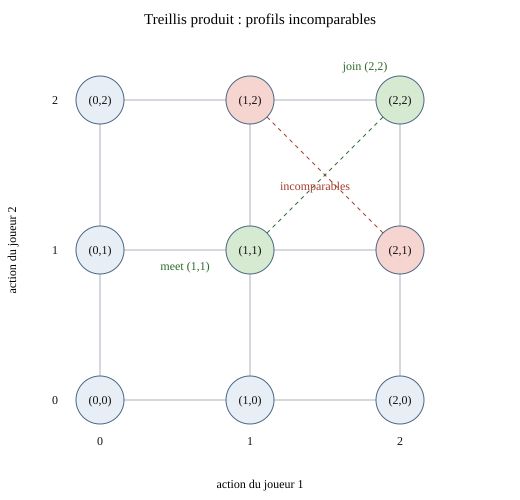

In [4]:
// Coordonnées calculées à partir des profils, sur fond opaque et axes gradués.
string BeginPlot(int width, int height, string title, string xlabel, string ylabel)
{
    return $"<svg xmlns='http://www.w3.org/2000/svg' width='{width}' height='{height}' viewBox='0 0 {width} {height}'><rect width='100%' height='100%' fill='white'/><text x='{width / 2}' y='24' text-anchor='middle' font-size='15'>{title}</text><text x='{width / 2}' y='{height - 12}' text-anchor='middle'>{xlabel}</text><text transform='translate(16,{height / 2}) rotate(-90)' text-anchor='middle'>{ylabel}</text>";
}
string Line(
    double x1,
    double y1,
    double x2,
    double y2,
    string color = "#aab4bf",
    string dash = ""
) => $"<line x1='{x1}' y1='{y1}' x2='{x2}' y2='{y2}' stroke='{color}' stroke-dasharray='{dash}'/>";
string Text(double x, double y, string text, string color = "#111") =>
    $"<text x='{x}' y='{y}' text-anchor='middle' font-size='12' fill='{color}'>{text}</text>";
string GridPlot(bool equilibrium, List<(int, int)> equilibria)
{
    var s = new StringBuilder(
        BeginPlot(
            520,
            500,
            equilibrium
                ? "Treillis des équilibres purs"
                : "Treillis produit : profils incomparables",
            "action du joueur 1",
            "action du joueur 2"
        )
    );
    double X(int a) => 100 + 150 * a;
    double Y(int b) => 400 - 150 * b;
    for (int k = 0; k < 3; k++)
    {
        s.Append(Line(X(k), 90, X(k), 410));
        s.Append(Line(90, Y(k), 410, Y(k)));
        s.Append(Text(X(k), 445, k.ToString()));
        s.Append(Text(55, Y(k) + 4, k.ToString()));
    }
    if (equilibrium)
    {
        foreach (var a in equilibria)
        foreach (var b in equilibria)
            if (
                a != b
                && Leq(a, b)
                && !equilibria.Any(z => z != a && z != b && Leq(a, z) && Leq(z, b))
            )
                s.Append(Line(X(a.Item1), Y(a.Item2), X(b.Item1), Y(b.Item2), "#4a6785"));
    }
    else
    {
        s.Append(Line(X(1), Y(2), X(2), Y(1), "#a33b2e", "4 4"));
        s.Append(Line(X(1), Y(1), X(2), Y(2), "#2d6a2d", "4 4"));
    }
    foreach (var p in Grid(3, 3))
    {
        bool active = equilibrium
            ? equilibria.Contains(p)
            : p == (1, 2) || p == (2, 1) || p == (1, 1) || p == (2, 2);
        string fill = equilibrium
            ? (active ? "#cfe0f2" : "white")
            : (
                p == (1, 2) || p == (2, 1) ? "#f6d5d0"
                : p == (1, 1) || p == (2, 2) ? "#d5ead0"
                : "#e8eef5"
            );
        s.Append(
            $"<circle cx='{X(p.Item1)}' cy='{Y(p.Item2)}' r='24' fill='{fill}' stroke='#4a6785'/>"
        );
        s.Append(Text(X(p.Item1), Y(p.Item2) + 4, $"({p.Item1},{p.Item2})"));
    }
    if (equilibrium)
    {
        s.Append(Text(150, 465, "bleu : équilibre pur ; blanc : non-équilibre"));
        s.Append(Text(155, 380, "plus petit", "#1f4e79"));
        s.Append(Text(345, 70, "plus grand", "#1f4e79"));
    }
    else
    {
        s.Append(Text(185, 270, "meet (1,1)", "#2d6a2d"));
        s.Append(Text(365, 70, "join (2,2)", "#2d6a2d"));
        s.Append(Text(315, 190, "incomparables", "#a33b2e"));
    }
    return s.Append("</svg>").ToString();
}

// La première figure ne dépend pas des équilibres calculés plus loin.
display(new Svg(GridPlot(false, new List<(int, int)>())));


### Interprétation : le meet et le join existent toujours, l'ordre total non

La figure rend visible une propriété que le vocabulaire courant masque : dans un
produit de chaînes, **deux éléments incomparables ont néanmoins un meet et un
join**, tous deux dans l'ensemble.

| Paire | Incomparable ? | Meet | Join |
|-------|----------------|------|------|
| $(1,2)$ et $(2,1)$ | oui | $(1,1)$ | $(2,2)$ |
| $(0,0)$ et $(2,2)$ | non (chaîne) | $(0,0)$ | $(2,2)$ |
| $(1,2)$ et $(1,2)$ | non (égalité) | $(1,2)$ | $(1,2)$ |

C'est la définition même d'un treillis : **toute** paire possède un meet et un
join. Un ensemble simplement trié serait un cas particulier (une chaîne), et le
théorème de la section 3 y serait vide de contenu.

> **Pourquoi cela compte pour les équilibria.** Le théorème de Topkis affirme que
> l'ensemble des équilibria purs d'un jeu supermodulaire est lui-même un treillis.
> Ce n'est pas une propriété automatique de tout ensemble d'équilibria : un jeu
> sans complémentarité peut avoir des équilibria disperses, sans meet ni join
> communs. La section 3 le vérifie sur un exemple concret.

## 2. Compléments et substituts stratégiques

### 2.1 Définition par la meilleure réponse

La supermodularité se lit sur les gains ; elle se **voit** sur la meilleure
réponse. Notons $BR_i(a_{-i})$ l'ensemble des actions de $i$ qui maximisent son
gain contre le profil $a_{-i}$.

| Structure | Condition sur les gains | Comportement de la meilleure réponse |
|-----------|-------------------------|--------------------------------------|
| **Compléments stratégiques** | différences croissantes en $(a_i, a_{-i})$ | $BR_i$ **croissante** : quand l'adversaire joue plus haut, je joue plus haut |
| **Substituts stratégiques** | différences décroissantes | $BR_i$ **décroissante** : quand l'adversaire joue plus haut, je joue plus bas |

Pour comparer deux ensembles de meilleures réponses, on utilise l'**ordre fort**
(de Veinott) : $S \le S'$ si, pour tout $s \in S$ et tout $s' \in S'$, on a
$\min(s,s') \in S$ et $\max(s,s') \in S'$. Même sur une chaîne, cet ordre ne se réduit pas à $\max(S) \le \min(S')$ : par exemple $S=S'=\{0,1\}$ satisfait la définition, mais $1 \nleq 0$.

> **Pourquoi l'ordre fort et pas l'inclusion ?** Une correspondance de meilleure
> réponse peut être multivaluée. L'ordre fort est la bonne notion pour dire
> << la réponse monte >> sans exiger que les ensembles grandissent ou rétrécissent.

### 2.2 Le jeu d'adoption avec externalité de réseau

Deux joueurs choisissent un standard : $A$ (ancien) ou $B$ (moderne).

- Jouer $A$ rapporte toujours $0$.
- Jouer $B$ contre $A$ rapporte $v - c$ (la valeur propre du moderne, moins son
  coût d'adoption).
- Jouer $B$ contre $B$ rapporte $v + n - c$ : s'ajoute l'**externalité de
  réseau** $n > 0$, qui n'existe que si les deux joueurs sont sur $B$.

Le terme $n \cdot \mathbf{1}[a_{-i} = B]$ crée exactement des différences
croissantes : la valeur marginale de choisir $B$ augmente quand l'autre choisit
$B$. C'est le prototype des compléments stratégiques.

In [5]:
// La correspondance conserve toutes les actions ex aequo.
int[] BestResponses(double[,] u, int b)
{
    double best = Enumerable.Range(0, u.GetLength(0)).Max(a => u[a, b]);
    return Enumerable.Range(0, u.GetLength(0)).Where(a => u[a, b] >= best - 1e-12).ToArray();
}
int[][] Correspondence(double[,] u) =>
    Enumerable.Range(0, u.GetLength(1)).Select(b => BestResponses(u, b)).ToArray();
bool StrongLeq(int[] s, int[] t) =>
    s.All(x => t.All(y => s.Contains(Math.Min(x, y)) && t.Contains(Math.Max(x, y))));
bool Increasing(int[][] br) =>
    Enumerable.Range(0, br.Length - 1).All(i => StrongLeq(br[i], br[i + 1]));
var adoptionA = new double[,]
{
    { 0, 0 },
    { .5, 1.5 },
};
var adoptionB = new double[,]
{
    { 0, .5 },
    { 0, 1.5 },
};
foreach (var (name, u) in new[] { ("Adoption", adoptionA), ("Cournot", cournot) })
{
    var br = Correspondence(u);
    Console.WriteLine(
        $"{name} : {string.Join(" ", br.Select(s => "{" + string.Join(",", s) + "}"))}"
    );
    Console.WriteLine(
        $"croissante : {Increasing(br)}, décroissante : {Increasing(br.Reverse().ToArray())}"
    );
}
Console.WriteLine($"Ordre fort {{0,1}} ≤ {{0,1}} : {StrongLeq(new[] { 0, 1 }, new[] { 0, 1 })}");


Adoption : {1} {1}


croissante : True, décroissante : True


Cournot : {5} {4,5} {4} {3,4} {3} {2,3} {2} {1,2} {1} {0,1}


croissante : False, décroissante : True


Ordre fort {0,1} ≤ {0,1} : True


### Interprétation : la monotonie de la meilleure réponse se lit dans la sortie

| Jeu | Correspondance de meilleure réponse | Verdict |
|-----|-------------------------------------|---------|
| Adoption | $BR(A) = \{B\}$, $BR(B) = \{B\}$ | croissante -> **compléments** |
| Cournot | $BR(0) = \{5\}$, $BR(1) = \{4,5\}$, $BR(2) = \{4\}$, ... | décroissante -> **substituts** |

Dans le jeu d'adoption, $B$ est une meilleure réponse **contre les deux** actions
adverses aux paramètres choisis ($v = 1$, $n = 1$, $c = 0.5$). La correspondance
est constante, donc croissante : c'est le cas le plus simple de compléments.

Dans Cournot, la meilleure réponse glisse vers le bas quand l'adversaire produit
davantage. La relation n'est pas seulement décroissante en moyenne : elle l'est
**au sens fort**, ce que le test vérifie paire par paire.

> **Cohérence avec la section 1.** Les verdicts de `Increasing` et de
> `IncreasingDifferences` coïncident sur les deux jeux.
> Les différences croissantes impliquent la monotonie de la correspondance sous les hypothèses de Topkis ; la réciproque est fausse. Pour $U=[[0,0],[2,1]]$, la meilleure réponse est constamment $\{1\}$, mais les gains marginaux passent de 2 à 1. La section 3 utilise l'hypothèse sur les gains.

### Exercice 2 — Compléments ou substituts ?

Soit le jeu $U = \begin{pmatrix} 0 & 3 \\ 2 & 0 \end{pmatrix}$, où chaque joueur
gagne à faire l'inverse de l'autre.

1. Calculer à la main $BR(0)$ et $BR(1)$ pour le joueur ligne.
2. Implémenter `classifyComplements` : renvoyer `"complements"` si la
   correspondance de meilleure réponse est croissante au sens fort,
   `"substituts"` si elle est décroissante, `"indetermine"` sinon.
3. Comparer le verdict avec celui de `IncreasingDifferences(U)`.

> **Indice :** `Correspondence` et `Increasing` sont déjà écrites en
> section 2. Pour le sens décroissant, tester la correspondance **renversée**
> (`brs.Reverse().ToArray()`) avec la même fonction.

> **TODO etudiant**

In [6]:
// Exercice 2 : déterminer la monotonie de la meilleure réponse.
Func<double[,], string> classifyComplements = u =>
{
    // TODO : calculer la correspondance, puis tester les deux sens.
    return null;
};
var ex2 = new double[,]
{
    { 0, 3 },
    { 2, 0 },
};
var nonMonotone = new double[,] { { 0, 1, 0 }, { 1, 0, 1 } };
var probes2 = new[] { ex2, threshold, cournot, nonMonotone };
var answers2 = probes2.Select(x => classifyComplements((double[,])x.Clone())).ToArray();
if (answers2.All(x => x == null))
    Console.WriteLine("Exercice 2 à compléter");
else
{
    for (int i = 0; i < probes2.Length; i++)
    {
        var br = Correspondence(probes2[i]);
        string expected =
            Increasing(br) ? "complements"
            : Increasing(br.Reverse().ToArray()) ? "substituts"
            : "indetermine";
        if (answers2[i] != expected)
            throw new Exception("Monotonie incorrecte");
    }
    Console.WriteLine("Exercice 2 : correspondances vérifiées");
}


Exercice 2 à compléter


## 3. Le treillis des équilibria purs

### 3.1 Le théorème

On dit qu'un jeu est **supermodulaire** si, pour chaque joueur $i$, le gain
$u_i(a_i, a_{-i})$ est supermodulaire en $(a_i, a_{-i})$ sur le treillis produit
des profils.

**Théorème (Topkis 1978 ; Milgrom et Roberts 1990 ; Vives 1990 ; Zhou 1994).**
Si un jeu fini est supermodulaire, alors l'ensemble de ses équilibria de Nash
**purs** est :

1. **non vide** ;
2. un **treillis complet** pour l'ordre composante par composante ;
3. en particulier, il possède un **plus petit** et un **plus grand** élément.

Le point 1 est le plus surprenant : la supermodularité suffit à garantir
l'existence d'un équilibre **pur**, sans recourir aux stratégies mixtes ni au
théorème de point fixe de [4c](GameTheory-04c-NashExistence-Python.ipynb). Le
point 2 est plus fin : ce n'est pas seulement << il existe un équilibre >>, c'est
<< l'ensemble des équilibria a une forme >>.

### 3.2 Un jeu où le treillis est visible

Reprenons le jeu de standard de la section 1 :

$$u_1(a, b) = \begin{cases} 2 & \text{si } a \ge 1 \text{ et } b \ge 1 \\ 0 & \text{sinon} \end{cases}$$

Le profil $(0,0)$ est un équilibre : aucun joueur ne gagne à moderniser **seul**.
C'est le **verrouillage** (*lock-in*). Mais dès que l'autre est sur une variante
moderne, toutes les variantes modernes se valent : le carré $\{1,2\} \times
\{1,2\}$ tout entier est un ensemble d'équilibria. L'ensemble des équilibria est
donc $\{(0,0)\} \cup \{1,2\}^2$ — cinq profils, dont deux incomparables.

In [7]:
// Une paire est un équilibre si aucun joueur ne peut améliorer seul son gain.
List<(int, int)> PureNash(double[,] a, double[,] b)
{
    int n = a.GetLength(0),
        m = a.GetLength(1);
    return Grid(n, m)
        .Where(p =>
            Enumerable.Range(0, n).All(i => a[p.Item1, p.Item2] >= a[i, p.Item2] - 1e-12)
            && Enumerable.Range(0, m).All(j => b[p.Item1, p.Item2] >= b[p.Item1, j] - 1e-12)
        )
        .ToList();
}
List<((int, int), (int, int))> ClosureFailures(List<(int, int)> eq)
{
    var set = eq.ToHashSet();
    var failures = new List<((int, int), (int, int))>();
    for (int i = 0; i < eq.Count; i++)
    for (int j = i + 1; j < eq.Count; j++)
        if (!set.Contains(Meet(eq[i], eq[j])) || !set.Contains(Join(eq[i], eq[j])))
            failures.Add((eq[i], eq[j]));
    return failures;
}
var equilibria = PureNash(threshold, threshold);
Console.WriteLine($"Équilibres purs : {string.Join(", ", equilibria)}");
Console.WriteLine(
    $"Nombre : {equilibria.Count} ; paires non closes : {ClosureFailures(equilibria).Count}"
);
Console.WriteLine($"Plus petit : {equilibria.First()} ; plus grand : {equilibria.Last()}");
Console.WriteLine($"(1,2) ∧ (2,1) = {Meet((1, 2), (2, 1))} ; ∨ = {Join((1, 2), (2, 1))}");


Équilibres purs : (0, 0), (1, 1), (1, 2), (2, 1), (2, 2)


Nombre : 5 ; paires non closes : 0


Plus petit : (0, 0) ; plus grand : (2, 2)


(1,2) ∧ (2,1) = (1, 1) ; ∨ = (2, 2)


### Interprétation : le treillis est vérifie, pas seulement annonce

La sortie donne les cinq équilibria purs et la clôture de toutes leurs paires :

| Propriété | Valeur observée |
|-----------|-----------------|
| Équilibria | $(0,0)$, $(1,1)$, $(1,2)$, $(2,1)$, $(2,2)$ |
| Plus petit | $(0,0)$ — présent dans l'ensemble |
| Plus grand | $(2,2)$ — présent dans l'ensemble |
| Paires non closes | **aucune** |

**Le point décisif est la paire incomparable.** $(1,2)$ et $(2,1)$ ne sont
ordonnes ni l'un ni l'autre ; pourtant leur meet $(1,1)$ et leur join $(2,2)$
sont **tous deux** des équilibria. Ici l'ensemble est clos sous les opérations ambiantes $\wedge$ et $\vee$, ce qui est plus fort que la seule propriété de treillis pour l'ordre induit : ses bornes peuvent en général différer des bornes ambiantes.

**Lecture économique.** Le plus petit équilibre $(0,0)$ est le **verrouillage sur
l'ancien standard** ; le plus grand $(2,2)$ est la **coordination sur le moderne**.
Entre les deux, tout le carré moderne est indifférent — les joueurs n'ont aucune
raison de se coordonner sur une variante plutot que l'autre, et le treillis
enregistre cette indifférence.

> **Ou sont les équilibria mixtes ?** Le théorème porte sur les équilibria
> **purs**. Un jeu supermodulaire peut aussi avoir des équilibria mixtes, mais
> l'énumération ci-dessus, comme `PureNash`, ne regarde que les profils
> purs. Le résultat de treillis est précisément intéressant parce qu'il garantit
> l'existence en pur.

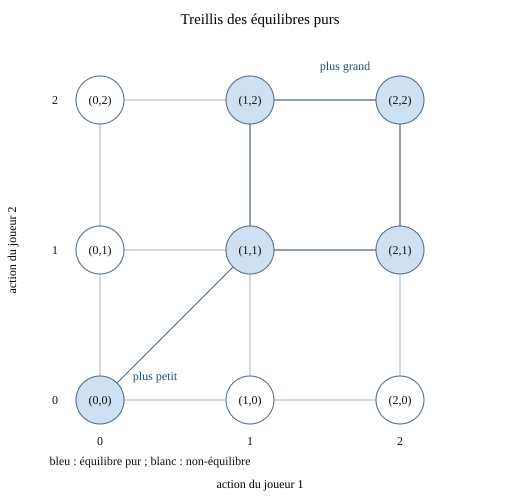

In [8]:
display(new Svg(GridPlot(true, equilibria)));


### Interprétation : lire le treillis comme un diagramme de Hasse

La figure trace les **couples couvrants** de l'ensemble des équilibria : une
arête relie deux équilibria comparables quand aucun autre équilibre ne s'intercale
entre eux. C'est la lecture standard d'un treillis fini.

| Élément | Rôle |
|---------|------|
| $(0,0)$ | plus petit équilibre : verrouillage sur l'ancien standard |
| $(2,2)$ | plus grand équilibre : coordination sur la variante haute |
| $(1,1)$ | meet de $(1,2)$ et $(2,1)$ |
| $(1,2)$, $(2,1)$ | incomparables, tous deux équilibria |

Les points hors de l'ensemble (cases vides) sont des profils qui ne sont **pas**
des équilibria : par exemple $(0,1)$, où le joueur 1 gagnerait à passer de $0$ à $1$ puisque le joueur 2 est déjà sur une variante moderne.

> **Un treillis n'est pas un arbre.** Le diagramme contient un carré : les deux
> chemins de $(1,1)$ à $(2,2)$ — par $(1,2)$ ou par $(2,1)$ — sont tous deux
> valides. C'est la signature visuelle de l'ordre partiel, et la raison pour
> laquelle << le plus grand >> et << le plus petit >> sont bien définis même
> quand il existe plusieurs éléments maximaux locaux.

### Exercice 3 — Vérifier la clôture d'un treillis

Soit le jeu symétrique de matrice :

$$U = \begin{pmatrix}
0 & 0 & 0 & 0 \\
0 & 2 & 2 & 2 \\
0 & 2 & 2 & 2 \\
0 & 2 & 3 & 4
\end{pmatrix}$$

1. Implémenter `latticeCheck` en réutilisant `PureNash` et `ClosureFailures`.
2. Renvoyer les équilibria purs, le nombre de paires non closes, le plus petit et
   le plus grand équilibre.
3. Interpréter : l'ensemble obtenu est-il un treillis ? Combien d'éléments
   contient-il, et lesquels ?

> **Indice :** les fonctions `PureNash` et `ClosureFailures` de la section 3 fournissent les objets à réunir dans le tuple demandé ; ne réécrivez pas la clôture.

> **TODO etudiant**
Le champ `Failures` est le **nombre** de paires non closes.


In [9]:
// Exercice 3 : restituer les équilibres, le nombre de défauts et les extrêmes.
Func<
    double[,],
    (List<(int, int)> Eq, int Failures, (int, int) Min, (int, int) Max)?
> latticeCheck = u =>
{
    // TODO : énumérer les équilibres et vérifier leur clôture.
    return null;
};
var ex3 = new double[,]
{
    { 0, 0, 0, 0 },
    { 0, 2, 2, 2 },
    { 0, 2, 2, 2 },
    { 0, 2, 3, 4 },
};
var nonClos = new double[,] { { 2, 0, 0 }, { 0, 0, 2 }, { 0, 2, 2 } };
var probes3 = new[] { ex3, threshold, nonClos };
var answers3 = probes3.Select(x => latticeCheck((double[,])x.Clone())).ToArray();
if (answers3.All(x => x == null))
    Console.WriteLine("Exercice 3 à compléter");
else
{
    for (int i = 0; i < probes3.Length; i++)
    {
        var e = PureNash(probes3[i], probes3[i]);
        var answer = answers3[i];
        if (
            answer == null
            || answer.Value.Eq == null
            || !answer.Value.Eq.OrderBy(x => x).SequenceEqual(e.OrderBy(x => x))
            || answer.Value.Failures != ClosureFailures(e).Count
            || answer.Value.Min != (e.Min(x => x.Item1), e.Min(x => x.Item2))
            || answer.Value.Max != (e.Max(x => x.Item1), e.Max(x => x.Item2))
        )
            throw new Exception("Bilan de treillis incorrect");
    }
    Console.WriteLine("Exercice 3 : treillis vérifiés");
}


Exercice 3 à compléter


## 4. Comparaison monotone des équilibria

### 4.1 Le second théorème

Les équilibria d'un jeu dépendent de paramètres : coût d'adoption, taxe,
productivité, subvention. La question naturelle est : **que fait un changement de paramètre à l'ensemble des équilibria ?**

**Théorème (comparaison monotone de Topkis).** Soit $\theta$ un paramètre tel que
chaque gain $u_i(a_i, a_{-i}, \theta)$ ait des différences croissantes en
$(a_i, \theta)$, en plus des différences croissantes en $(a_i, a_{-i})$. Alors le
plus petit et le plus grand équilibre pur sont **non décroissants** en $\theta$.

Autrement dit : si le paramètre rend l'action haute relativement plus attractive,
les équilibres extrêmes ne peuvent que **monter**. Ils peuvent rester sur place,
mais jamais descendre — et c'est tout ce que le théorème promet.

> **Ce que le théorème ne dit pas.** Il ne dit rien de la continuité : les
> équilibres extrêmes peuvent **sauter** d'un niveau à l'autre quand le paramètre
> franchit un seuil. Une fonction non décroissante peut avoir des marches. La
> section 4.2 en montre un exemple.

### 4.2 Une subvention au standard moderne

Reprenons le jeu d'adoption et interprétons $\theta$ comme la **valeur du
standard moderne** (subvention, gain de productivité). Le coût d'adoption de base
est $c_0 = 2$ et l'externalité de réseau vaut $n = 1$ :

- $u_1(A, \cdot) = 0$ ;
- $u_1(B, A) = \theta - c_0$ ;
- $u_1(B, B) = \theta + n - c_0$.

Le paramètre $\theta$ entre dans le gain de $B$ seulement : la différence
$u_1(B, \cdot) - u_1(A, \cdot)$ croit avec $\theta$, donc les différences
croissantes en $(a_1, \theta)$ sont satisfaites.

In [10]:
// Les deux extrêmes sont comparés à chaque valeur du paramètre.
(double[,], double[,]) Adoption(double theta, double cost = 2, double network = 1)
{
    double ba = theta - cost,
        bb = theta + network - cost;
    return (
        new double[,]
        {
            { 0, 0 },
            { ba, bb },
        },
        new double[,]
        {
            { 0, ba },
            { 0, bb },
        }
    );
}
((int, int) Min, (int, int) Max, List<(int, int)> All) Extremes(
    double theta,
    double cost = 2,
    double network = 1
)
{
    var (a, b) = Adoption(theta, cost, network);
    var eq = PureNash(a, b);
    return (
        (eq.Min(x => x.Item1), eq.Min(x => x.Item2)),
        (eq.Max(x => x.Item1), eq.Max(x => x.Item2)),
        eq
    );
}
var thetas = new[] { 0.0, .5, 1, 1.5, 2, 2.5, 3 };
(int, int)? previousMin = null,
    previousMax = null;
foreach (double t in thetas)
{
    var e = Extremes(t);
    if (previousMin.HasValue && (!Leq(previousMin.Value, e.Min) || !Leq(previousMax.Value, e.Max)))
        throw new Exception("Monotonie violée");
    Console.WriteLine($"{t:F2} : {string.Join(", ", e.All)} ; minimum {e.Min} ; maximum {e.Max}");
    previousMin = e.Min;
    previousMax = e.Max;
}
Console.WriteLine("Coexistence sur [1,2] ; les extrêmes sont non décroissants.");


0.00 : (0, 0) ; minimum (0, 0) ; maximum (0, 0)


0.50 : (0, 0) ; minimum (0, 0) ; maximum (0, 0)


1.00 : (0, 0), (1, 1) ; minimum (0, 0) ; maximum (1, 1)


1.50 : (0, 0), (1, 1) ; minimum (0, 0) ; maximum (1, 1)


2.00 : (0, 0), (1, 1) ; minimum (0, 0) ; maximum (1, 1)


2.50 : (1, 1) ; minimum (1, 1) ; maximum (1, 1)


3.00 : (1, 1) ; minimum (1, 1) ; maximum (1, 1)


Coexistence sur [1,2] ; les extrêmes sont non décroissants.


### Interprétation : une bande de coexistence, pas une bascule nette

Le tableau montre trois régimes :

| Plage de $\theta$ | Équilibria | Plus petit | Plus grand |
|-------------------|------------|------------|------------|
| $\theta < 1$ | $\{(A,A)\}$ | $A$ | $A$ |
| $1 \le \theta \le 2$ | $\{(A,A), (B,B)\}$ | $A$ | $B$ |
| $\theta > 2$ | $\{(B,B)\}$ | $B$ | $B$ |

**Pourquoi une bande ?** Entre $\theta = 1$ et $\theta = 2$, chacun des deux
profils est un équilibre :

- $(A,A)$ tient parce que moderniser seul ne vaut pas le coût : $u_1(B,A) =
  \theta - 2 \le 0$ ;
- $(B,B)$ tient parce que la coordination rend le moderne rentable : $u_1(B,B) =
  \theta - 1 \ge 0$.

La largeur de la bande est exactement l'externalité de réseau $n = 1$. Plus le
réseau est fort, plus la **coexistence** est large — et plus le système peut
rester bloqué sur l'ancien standard alors que le nouveau serait collectivement
meilleur.

> **Deux lecteurs du même théorème.** Le plus grand équilibre bascule à
> $\theta = 1$ ; le plus petit à $\theta = 2$. Les deux sont non décroissants,
> conformément au théorème, mais ils ne basculent **pas au même seuil** : c'est
> précisément la coexistence qui distingue les deux fonctions. Une politique qui
> ne regarde que l'équilibre le plus favorable surestime la facilité du
> basculement.

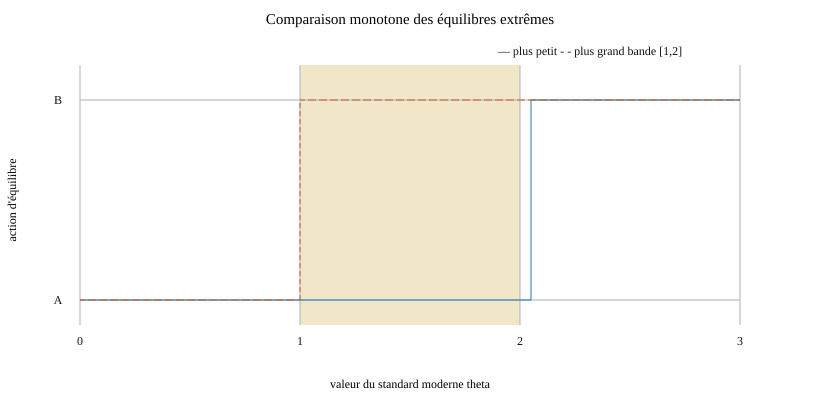

In [11]:
// Le tracé en escalier est calculé pour les 61 valeurs de theta de la source.
var thetaGrid = Enumerable.Range(0, 61).Select(i => 3.0 * i / 60).ToArray();
var measures = thetaGrid.Select(t => Extremes(t)).ToArray();
var chart = new StringBuilder(
    BeginPlot(
        820,
        400,
        "Comparaison monotone des équilibres extrêmes",
        "valeur du standard moderne theta",
        "action d'équilibre"
    )
);
double PX(double t) => 80 + 220 * t;
double PY(int v) => 300 - 200 * v;
chart.Append("<rect x='300' y='65' width='220' height='260' fill='#f2e6c9'/>");
for (int i = 0; i <= 3; i++)
{
    chart.Append(Line(PX(i), 65, PX(i), 325));
    chart.Append(Text(PX(i), 345, i.ToString()));
}
for (int i = 0; i <= 1; i++)
{
    chart.Append(Line(80, PY(i), 740, PY(i)));
    chart.Append(Text(58, PY(i) + 4, i == 0 ? "A" : "B"));
}
for (int i = 0; i < 60; i++)
{
    chart.Append(
        Line(
            PX(thetaGrid[i]),
            PY(measures[i].Min.Item1),
            PX(thetaGrid[i + 1]),
            PY(measures[i].Min.Item1),
            "#1f77b4"
        )
    );
    chart.Append(
        Line(
            PX(thetaGrid[i + 1]),
            PY(measures[i].Min.Item1),
            PX(thetaGrid[i + 1]),
            PY(measures[i + 1].Min.Item1),
            "#1f77b4"
        )
    );
    chart.Append(
        Line(
            PX(thetaGrid[i]),
            PY(measures[i].Max.Item1),
            PX(thetaGrid[i + 1]),
            PY(measures[i].Max.Item1),
            "#d05b23",
            "5 3"
        )
    );
    chart.Append(
        Line(
            PX(thetaGrid[i + 1]),
            PY(measures[i].Max.Item1),
            PX(thetaGrid[i + 1]),
            PY(measures[i + 1].Max.Item1),
            "#d05b23",
            "5 3"
        )
    );
}
chart.Append(Text(590, 55, "— plus petit    - - plus grand    bande [1,2]"));
chart.Append("</svg>");
display(new Svg(chart.ToString()));


### Interprétation : des marches, pas une pente

La figure trace deux fonctions **en escalier** du paramètre $\theta$ :

| Fonction | Seuil de bascule | Lecture |
|----------|------------------|---------|
| Plus petit équilibre | $\theta = 2$ | en dessous, le verrouillage $(A,A)$ survit |
| Plus grand équilibre | $\theta = 1$ | dès que le moderne est rentable sous coordination, $(B,B)$ apparaît |

Les deux courbes sont non décroissantes : elles montent ou restent plates, jamais
l'inverse. C'est exactement l'énoncé du théorème — et l'absence de continuité
n'est pas une violation : le théorème porte sur la **monotonie**, pas sur la
continuité.

> **Test de compréhension.** Si l'on supprimait l'externalité de réseau ($n = 0$),
> que deviendrait la bande de coexistence ? Réponse attendue : elle se réduit à un
> point ($\theta = c_0$), les deux seuils se confondent, et la bascule redevient
> nette. L'exercice 4 fait varier ce paramètre.

### Exercice 4 — Comparaison monotone avec une autre externalité

On reprend le jeu d'adoption, mais avec un coût d'adoption $c_0 = 1$ et une
externalité de réseau $n = 1.5$ :

- $u_1(A, \cdot) = 0$ ;
- $u_1(B, A) = t - 1$ ;
- $u_1(B, B) = t + 0.5$.

1. Implémenter `checkStatics` : pour chaque valeur de $t$ fournie,
   calculer les équilibres extrêmes, vérifier qu'**aucun ne descend** par rapport à la valeur précédente, et identifier les valeurs de $t$ ou les deux
   équilibres coexistent.
2. En déduire la **bande de coexistence** et sa largeur.
3. Comparer avec la section 4.2 : la largeur de la bande vaut-elle bien
   l'externalité de réseau $n$ ?

> **Indice :** `Extremes(t, 1, 1.5)` renvoie `(Min, Max, All)`. La coexistence
> se lit directement sur `All.Count == 2`.

> **TODO etudiant**
Renvoyez le tuple `Monotone` et `Coexistence` (tableau des valeurs dans l’ordre fourni).


In [12]:
// Exercice 4 : calculer la monotonie et les valeurs de coexistence pour n=1,5.
Func<double[], (bool Monotone, double[] Coexistence)?> checkStatics = values =>
{
    // TODO : comparer les extrêmes successifs et relever les deux équilibres.
    return null;
};
var probes4 = new[]
{
    new[] { -1.0, -.5, 0, .5, 1, 1.5, 2 },
    new[] { -1.0, 0, 2 },
    new[] { 2.0, 0, -1 },
};
var answers4 = probes4.Select(x => checkStatics((double[])x.Clone())).ToArray();
if (answers4.All(x => x == null))
    Console.WriteLine("Exercice 4 à compléter");
else
{
    for (int i = 0; i < probes4.Length; i++)
    {
        var measures4 = probes4[i].Select(t => Extremes(t, 1, 1.5)).ToArray();
        bool monotone = Enumerable
            .Range(1, measures4.Length - 1)
            .All(j =>
                Leq(measures4[j - 1].Min, measures4[j].Min)
                && Leq(measures4[j - 1].Max, measures4[j].Max)
            );
        var coexist = probes4[i].Where((t, j) => measures4[j].All.Count == 2).ToArray();
        var answer = answers4[i];
        if (
            answer == null
            || answer.Value.Monotone != monotone
            || answer.Value.Coexistence == null
            || !answer.Value.Coexistence.SequenceEqual(coexist)
        )
            throw new Exception("Comparaison incorrecte");
    }
    Console.WriteLine("Exercice 4 : comparaisons vérifiées");
}


Exercice 4 à compléter


## 5. Ce que ce treillis n'est pas : les matchings stables

### 5.1 Deux treillis, deux ordres

La série contient déjà un treillis, mais c'est un **autre objet**. Le module Lean
`game_theory_lean/StableMarriage/Lattice.lean` traite le treillis de **Roth** :
les matchings stables d'un marché à deux côtés.

| | Treillis des équilibria (ce carnet) | Treillis des matchings stables |
|---|---|---|
| Objets | profils d'actions $(a_1, \dots, a_n)$ | appariements entre deux côtés |
| Ordre | **composante par composante** : $a \le a'$ si $a_i \le a'_i$ pour tout $i$ | **par préférences** : $M \le M'$ si chaque agent d'un côté préfère son partenaire dans $M'$ |
| Origine de la structure | la **forme des gains** (complémentarité) | les **préférences** des agents |
| Théorème | Topkis, Milgrom-Roberts, Zhou | Gale-Shapley, Roth |
| Extrêmes | plus petit / plus grand équilibre | optimal pour un côté / optimal pour l'autre |

**La différence décisive** : dans le treillis des équilibria, l'ordre est
**extrinsèque** — il vient de l'ordre numérique des actions, pas des gains. Dans
le treillis des matchings, l'ordre est **intrinsèque** — il est **défini** par
les préférences : il n'existe pas d'ordre << naturel >> sur les appariements.

### 5.2 Vérifier la différence sur une instance

Prenons deux hommes et deux femmes, avec des préférences croisées :

- $m_1 : w_1 \succ w_2$ et $m_2 : w_2 \succ w_1$ ;
- $w_1 : m_2 \succ m_1$ et $w_2 : m_1 \succ m_2$.

On énumère les deux appariements possibles, on teste la stabilité de chacun, et on
compare les deux issues de Gale-Shapley (hommes proposants, femmes proposantes).

In [13]:
// Gale-Shapley : chaque proposant libre avance dans sa liste ; un receveur garde son préféré.
Dictionary<string, string> GaleShapley(
    Dictionary<string, string[]> proposers,
    Dictionary<string, string[]> receivers
)
{
    var next = proposers.Keys.ToDictionary(x => x, x => 0);
    var owner = new Dictionary<string, string>();
    var free = new Queue<string>(proposers.Keys.OrderBy(x => x));
    while (free.Count > 0)
    {
        string p = free.Dequeue(),
            r = proposers[p][next[p]++];
        if (!owner.TryGetValue(r, out var old))
            owner[r] = p;
        else if (Array.IndexOf(receivers[r], p) < Array.IndexOf(receivers[r], old))
        {
            owner[r] = p;
            free.Enqueue(old);
        }
        else
            free.Enqueue(p);
    }
    return owner.ToDictionary(x => x.Value, x => x.Key);
}
bool Stable(
    Dictionary<string, string> matching,
    Dictionary<string, string[]> pp,
    Dictionary<string, string[]> rp
)
{
    var inverse = matching.ToDictionary(x => x.Value, x => x.Key);
    foreach (var p in pp.Keys)
    foreach (var r in pp[p].TakeWhile(r => r != matching[p]))
        if (Array.IndexOf(rp[r], p) < Array.IndexOf(rp[r], inverse[r]))
            return false;
    return true;
}
var men = new Dictionary<string, string[]>
{
    { "m1", new[] { "w1", "w2" } },
    { "m2", new[] { "w2", "w1" } },
};
var women = new Dictionary<string, string[]>
{
    { "w1", new[] { "m2", "m1" } },
    { "w2", new[] { "m1", "m2" } },
};
var matches = new[]
{
    new Dictionary<string, string> { { "m1", "w1" }, { "m2", "w2" } },
    new Dictionary<string, string> { { "m1", "w2" }, { "m2", "w1" } },
};
foreach (var m in matches)
    Console.WriteLine(
        $"{string.Join(", ", m.Select(x => $"{x.Key}→{x.Value}"))} : stable={Stable(m, men, women)}"
    );
var menOptimal = GaleShapley(men, women);
var womenOptimal = GaleShapley(women, men);
Console.WriteLine(
    $"Hommes proposants : {string.Join(", ", menOptimal.Select(x => $"{x.Key}→{x.Value}"))}"
);
Console.WriteLine(
    $"Femmes proposantes : {string.Join(", ", womenOptimal.Select(x => $"{x.Key}→{x.Value}"))}"
);


m1→w1, m2→w2 : stable=True


m1→w2, m2→w1 : stable=True


Hommes proposants : m1→w1, m2→w2


Femmes proposantes : w1→m2, w2→m1


### Interprétation : deux treillis, deux natures d'ordre

La sortie confirme qu'il y a exactement **deux** matchings stables, et qu'ils
coïncident avec les deux issues de Gale-Shapley :

| Matching | Hommes proposants | Femmes proposantes |
|----------|-------------------|--------------------|
| $m_1 \leftrightarrow w_1$, $m_2 \leftrightarrow w_2$ | oui (optimal pour les hommes) | non |
| $m_1 \leftrightarrow w_2$, $m_2 \leftrightarrow w_1$ | non | oui (optimal pour les femmes) |

**Le contraste avec la section 3 est net :**

- Dans le treillis des équilibria, comparer $(1,1)$ et $(2,2)$ ne demande aucune
  préférence : $1 \le 2$ et $1 \le 2$, donc $(1,1) \le (2,2)$. L'ordre existe
  **avant** les agents.
- Dans le treillis des matchings, comparer les deux matchings stables **exige de
  choisir un côté**. Le premier est plus grand pour les hommes, le second pour les
  femmes ; il n'y a pas d'ordre qui les classe tous les deux de la même façon.

> **Pourquoi cette section existe.** Le mot << treillis >> apparaît déjà dans la
> série, mais il désignait jusqu'ici le treillis de Roth. Sans cette distinction,
> un lecteur pourrait croire que les deux résultats sont le même théorème applique
> deux fois. Ce sont deux théorèmes distincts, sur deux structures distinctes,
> avec deux notions d'ordre distinctes.

## 6. Exercices

Les quatre activités sont distribuées dans le fil du carnet : elles réutilisent les fonctions des sections précédentes pour classifier, vérifier et interpréter. Les cellules restent ouvertes tant que les fonctions ne sont pas complétées.

1. **Classifier un jeu par ses gains** : tester la structure de supermodularité et les différences croisées après la section 1.4.
2. **Compléments ou substituts ?** : relier le sens de la meilleure réponse aux propriétés des gains après la section 2.
3. **Vérifier la clôture d’un treillis** : éprouver meet et join sur les équilibres purs après la section 3.
4. **Comparaison monotone avec une autre externalité** : examiner le déplacement des équilibres lorsque le paramètre varie après la section 4.

Chaque activité conserve son énoncé, ses indices et sa cellule à compléter à l’endroit où le mécanisme est introduit ; ce récapitulatif ne fournit aucune solution.


## À retenir

Ce carnet a remplace la question << **y a-t-il** un équilibre ? >> (carnet 4c) par
la question << **quelle est la forme** de l'ensemble des équilibria ? >>.

| Section | Résultat | Vérification |
|---------|----------|--------------|
| 1 | treillis produit, supermodularité, différences croissantes | tests exhaustifs sur 9 et 100 profils |
| 1 | lemme de Topkis : les deux tests sont équivalents sur une chaîne finie | les deux verdicts concordent sur les deux jeux |
| 2 | différences croissantes impliquent une meilleure réponse croissante | correspondances affichées et testées à l'ordre fort |
| 3 | l'ensemble des équilibria purs d'un jeu supermodulaire est un treillis complet | 5 équilibria, 0 paire non close, meet et join vérifiés |
| 4 | les équilibres extrêmes sont non décroissants en un paramètre | tableau de 7 valeurs + courbes en escalier |
| 5 | le treillis des équilibria n'est pas le treillis des matchings | 2 matchings stables, ordres par des préférences |

**Les trois idées à retenir :**

1. **La complémentarité est une propriété de la forme des gains**, pas du nombre
   d'équilibres. Elle se lit sur une matrice, par différences croissantes.
2. **Un jeu supermodulaire a toujours un équilibre pur**, et son ensemble
   d'équilibria est structuré : plus petit, plus grand, et treillis complet pour l'ordre induit. La clôture par meet et join ambiants est vérifiée ici pour l'instance.
3. **La comparaison monotone éclaire une possibilité d'hystérésis** : quand deux équilibres
   coexistent, le système peut rester bloqué sur le plus petit alors qu'un
   paramètre a déjà franchi le seuil du plus grand.

> **Ce que le carnet ne traite pas.** Les jeux à plus de deux joueurs, les
> actions continues et les extensions infinies demandent des arguments de
> compacité que le cadre fini évite ; les jeux globaux (sélection d'équilibre par
> information incomplète) font l'objet d'un carnet dédié. Le treillis des
> matchings stables est traite dans le module Lean `game_theory_lean/StableMarriage/Lattice.lean`.

## Vérifiez votre compréhension

1. Le jeu « standard / modernisation » passe les deux tests (violations = `(0, 0)`), Cournot échoue aux deux (violations = `(4050, 2025)`). Que mesure ce compteur de violations ?

   <details><summary>Réponse</summary>

   Le premier compteur énumère les **paires ordonnées de profils** violant la supermodularité ; le second compte les **rectangles stricts** violant les différences croissantes. Aucun ne compte les équilibres. Zéro violation signifie que la condition est vérifiée **exhaustivement** sur toutes les paires du jeu — c'est le lemme de Topkis vérifié, et non postulé. À l'inverse, les `(4050, 2025)` de Cournot disent que la structure de substituts n'obéit pas à la condition.

   </details>

2. Le jeu d'adoption affiche une meilleure réponse à la fois croissante et décroissante à l'ordre fort, alors que Cournot n'affiche que la décroissante. Comment lire ce résultat ?

   <details><summary>Réponse</summary>

   Les deux tables se séparent par le test qui les **distingue** : l'adoption a une meilleure réponse qui monte avec l'action de l'adversaire (compléments), Cournot une qui descend (substituts). Le double drapeau de l'adoption tient à la forme de sa correspondance (`BR(b), pour b = 0..1 : [(1,), (1,)]`) : sur les deux points comparés, elle ne se déplace pas. Le test discriminant reste « croissante : True » côté adoption, « False » côté Cournot.

   </details>

3. Le jeu symétrique a cinq équilibria purs, dont les deux points incomparables `(1, 2)` et `(2, 1)`, et le carnet vérifie que `(1, 2) ^ (2, 1) = (1, 1)` et `(1, 2) v (2, 1) = (2, 2)` sont eux-mêmes des équilibres. Qu'est-ce que cela prouve ?

   <details><summary>Réponse</summary>

   Que l'ensemble des équilibria purs est **clos** sous le meet et le join : prendre deux équilibria incomparables et en fabriquer un troisième, par le bas puis par le haut, reste un équilibre. Avec « Paires non closes : aucune », le plus petit `(0, 0)` et le plus grand `(2, 2)`, l'ensemble est un **treillis complet** — pas seulement une collection d'équilibres.

   </details>

4. La subvention fait apparaître une bande `theta` dans `[1, 2]` où les deux équilibres coexistent. Comment l'interpréter ?

   <details><summary>Réponse</summary>

   Comme une **possibilité d'hystérésis**, sans simulation d'une dynamique : le tableau montre `[(0, 0)]` jusqu'à theta = 0.50, `[(0, 0), (1, 1)]` de theta = 1.00 à 2.00, puis `[(1, 1)]` seul à partir de theta = 2.50. Pendant la bande, le système peut rester bloqué sur le plus petit équilibre alors que le paramètre a déjà franchi le seuil du plus grand — les deux extrêmes ne descendant jamais en theta.

   </details>


## Pour aller plus loin

**Carnet suivant.** [GameTheory-04h — Routing et prix de l'anarchie](GameTheory-04h-Routing-PriceOfAnarchy-Python.ipynb) -- le versant coût de l'équilibre : quand le prix de l'anarchie remplace le gain, la question n'est plus « quel équilibre » mais « quelle perte collectivement acceptée ».

**Lectures.**

- Les références complètes du carnet sont dans la section « Références académiques » : Topkis (1978) pour la comparaison monotone des optimiseurs paramétrés, Milgrom & Roberts (1990) et Vives (1990) pour les compléments stratégiques, Zhou (1994) pour la complétude du treillis, et Gale & Shapley (1962) / Roth & Sotomayor (1990) pour le treillis **des matchings stables** — l'autre treillis de la série, ordonné par préférences et non par composantes.
- Le module Lean `game_theory_lean/StableMarriage/Lattice.lean` traite ce second treillis côté formel : c'est le prolongement naturel du carnet.

**Carnets voisins.**

- [GameTheory-04 — Nash](GameTheory-04-NashEquilibrium-Python.ipynb) -- le track principal : l'équilibre comme point, là où ce carnet le traite comme ensemble.
- [GameTheory-04c — NashExistence](GameTheory-04c-NashExistence-Python.ipynb) -- l'existence par point fixe, question que la structure de treillis rend plus fine.
- [GameTheory-04b — Lean NashExistence](GameTheory-04b-Lean-NashExistence-Lean.ipynb) -- l'existence en Lean.
- [GameTheory-04e — Oracles réflexifs](GameTheory-04e-Reflective-Oracles-Python.ipynb) -- l'auto-référence computationnelle, autre source de structure.


## Références académiques

- **Topkis, D.M.** (1978). *Minimizing a Submodular Function on a Lattice*.
  Operations Research 26(2):305-321. — Le théorème de comparaison monotone pour
  les optimiseurs paramètres, fondement des sections 3 et 4.
- **Milgrom, P. et Roberts, J.** (1990). *Rationalizability, Learning, and
  Equilibrium in Games with Strategic Complementarities*. Econometrica
  58(6):1255-1277. — Les compléments stratégiques et le treillis des équilibria.
- **Vives, X.** (1990). *Nash Equilibrium with Strategic Complementarities*.
  Journal of Mathematical Economics 19(3):305-321. — Existence et comparaison
  dans les jeux à compléments.
- **Zhou, L.** (1994). *The Set of Nash Équilibria of a Supermodular Game is a
  Complete Lattice*. Games and Economic Behavior 7(2):295-300. — La complétude du treillis pour l'ordre induit, illustrée en section 3.
- **Gale, D. et Shapley, L.S.** (1962). *College Admissions and the Stability of
  Marriage*. American Mathematical Monthly 69(1):9-15. — L'algorithme de
  Gale-Shapley, réutilise en section 5.
- **Roth, A.E. et Sotomayor, M.A.O.** (1990). *Two-Sided Matching: A Study in
  Game-Theoretic Modeling and Analysis*. Cambridge University Press. — Le
  treillis des matchings stables, distingue en section 5.

**Prolongements dans la série :** [4c (existence par point fixe)](GameTheory-04c-NashExistence-Python.ipynb) . [4b (existence en Lean)](GameTheory-04b-Lean-NashExistence-Lean.ipynb)

***

**Navigation** : [<< 4e-Reflective-Oracles](GameTheory-04e-Reflective-Oracles-Python.ipynb) | [Index](README.md)

**Autres approfondissements de 04** : [4-NashEquilibrium (track principal)](GameTheory-04-NashEquilibrium-Python.ipynb) · [4b-Lean-NashExistence](GameTheory-04b-Lean-NashExistence-Lean.ipynb) · [4c-NashExistence](GameTheory-04c-NashExistence-Python.ipynb) · [4d-Marchandage-Asymetrique](GameTheory-04d-Marchandage-Asymetrique-Python.ipynb) · [4e-Reflective-Oracles](GameTheory-04e-Reflective-Oracles-Python.ipynb) · [4h-Routing-PriceOfAnarchy](GameTheory-04h-Routing-PriceOfAnarchy-Python.ipynb)